# 03. Исследовательский анализ: рынок труда Кыргызстана (начало 2024)

Анализ построен вокруг вопросов, а не графиков. На каждый вопрос: график → короткий вывод.

1. Сколько платят на рынке и чем отличаются hh и lalafo?
2. Какие сферы платят больше всего?
3. Сколько добавляет опыт?
4. Бишкек против регионов
5. Кто скрывает зарплату?
6. Какие навыки повышают зарплату?
7. Влияет ли требование к образованию на зарплату?
8. Требования к полу в объявлениях
9. Дневная оплата и графики работы
10. Что из этого важно для модели

**Везде используем медиану**, а не среднее: зарплаты скошены вправо, несколько высоких
значений сильно сдвигают среднее. Группы меньше 30 зарплат не показываем — по ним выводы ненадёжны.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 60)
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")

df = pd.read_csv("../data/processed/vacancies_clean.csv", parse_dates=["published"])
sal = df[df["has_salary"]].copy()
MIN_N = 30
print(f"Вакансий: {len(df)} | с зарплатой: {len(sal)}")

def median_by(col, data=sal, min_n=MIN_N):
    g = data.groupby(col)["salary_kgs"].agg(median="median", n="size")
    return g[g["n"] >= min_n].sort_values("median")

Вакансий: 12646 | с зарплатой: 5840


## 1. Сколько платят и чем отличаются hh и lalafo

In [2]:
print("Медиана по рынку:", f"{sal['salary_kgs'].median():,.0f} сом")
median_by("source")

Медиана по рынку: 39,000 сом


,median,n
source,,
lalafo,35000.0,3812
headhunter,40000.0,2028


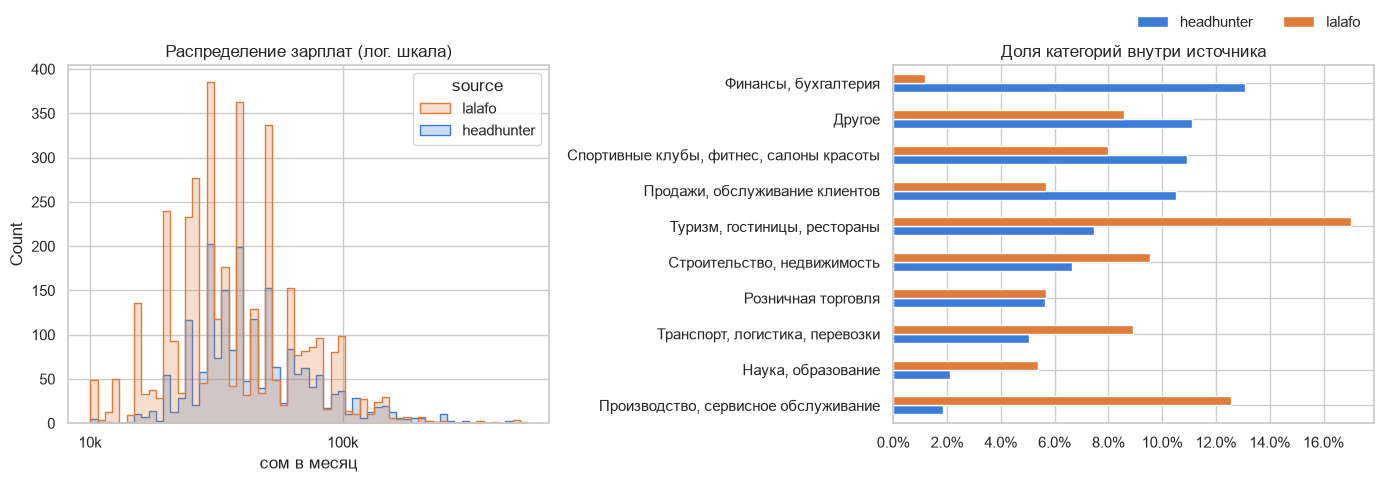

In [3]:
PAL = {"headhunter": "#3b7dd8", "lalafo": "#e07b39"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(sal, x="salary_kgs", hue="source", palette=PAL, bins=60, log_scale=True,
             element="step", ax=ax[0])
ax[0].xaxis.set_major_formatter(K); ax[0].set_title("Распределение зарплат (лог. шкала)")
ax[0].set_xlabel("сом в месяц")

mix = pd.crosstab(df["category"], df["source"], normalize="columns")
top = mix.max(axis=1).sort_values(ascending=False).head(10).index
mix.loc[top].sort_values("headhunter")[["headhunter", "lalafo"]].plot(
    kind="barh", ax=ax[1], color=[PAL["headhunter"], PAL["lalafo"]])
ax[1].set_title("Доля категорий внутри источника"); ax[1].xaxis.set_major_formatter(mt.PercentFormatter(1))
ax[1].set_ylabel(""); ax[1].legend(title="", loc="lower right", bbox_to_anchor=(1, 1.06), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig(FIG + "03_q1_sources.png", dpi=150); plt.show()

**Вывод:** медиана рынка — 39 000 сом. hh платит больше lalafo (40 000 против 35 000) и состоит из
других вакансий: офис и продажи против услуг, общепита и производства. Это по сути два рынка,
поэтому источник — обязательный признак для модели.

## 2. Какие сферы платят больше всего

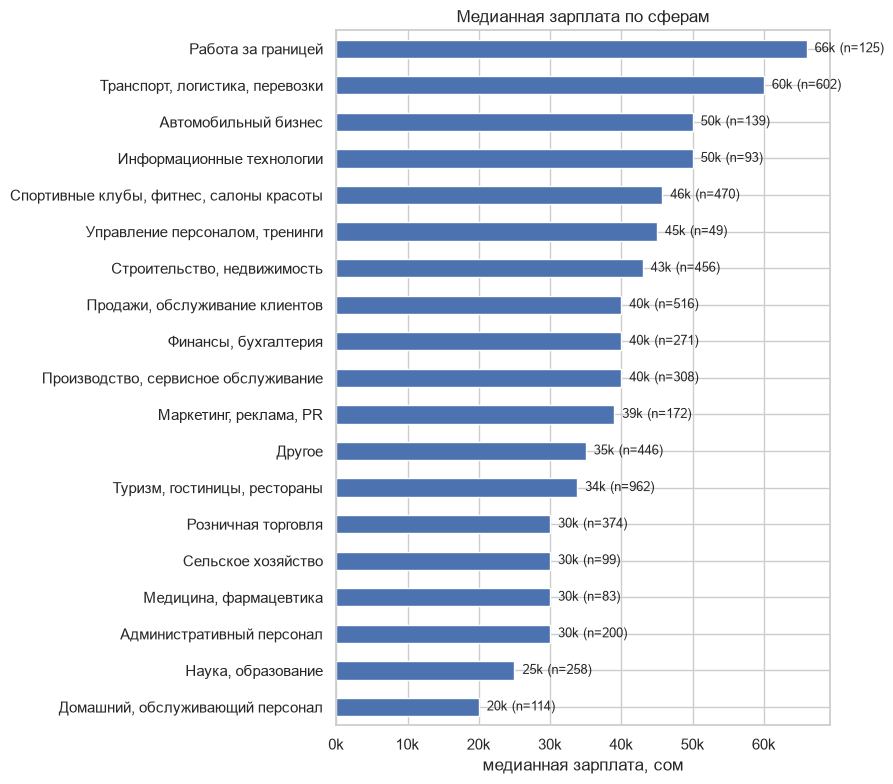

,median,n
category,,
"Спортивные клубы, фитнес, салоны красоты",45750.0,470
Информационные технологии,50000.0,93
Автомобильный бизнес,50000.0,139
"Транспорт, логистика, перевозки",60000.0,602
Работа за границей,66000.0,125


In [4]:
cat = median_by("category")
ax = cat["median"].plot(kind="barh", figsize=(9, 8))
for i, (m, n) in enumerate(zip(cat["median"], cat["n"])):
    ax.text(m, i, f"  {m/1000:.0f}k (n={n})", va="center", fontsize=9)
ax.xaxis.set_major_formatter(K); ax.set_xlabel("медианная зарплата, сом")
ax.set_title("Медианная зарплата по сферам"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG + "03_q2_categories.png", dpi=150); plt.show()
cat.tail(5)

## 3. Сколько добавляет опыт

In [5]:
order = ["нет опыта", "1–3 года", "3–6 лет", "6+ лет"]
exp = sal.groupby("experience")["salary_kgs"].agg(["median", "size"]).reindex(order)
exp["к_без_опыта"] = (exp["median"] / exp.loc["нет опыта", "median"]).round(2)
exp

,median,size,к_без_опыта
experience,,,
нет опыта,32500.0,2606,1.00
1–3 года,39140.0,2414,1.20
3–6 лет,50000.0,604,1.54
6+ лет,45000.0,216,1.38


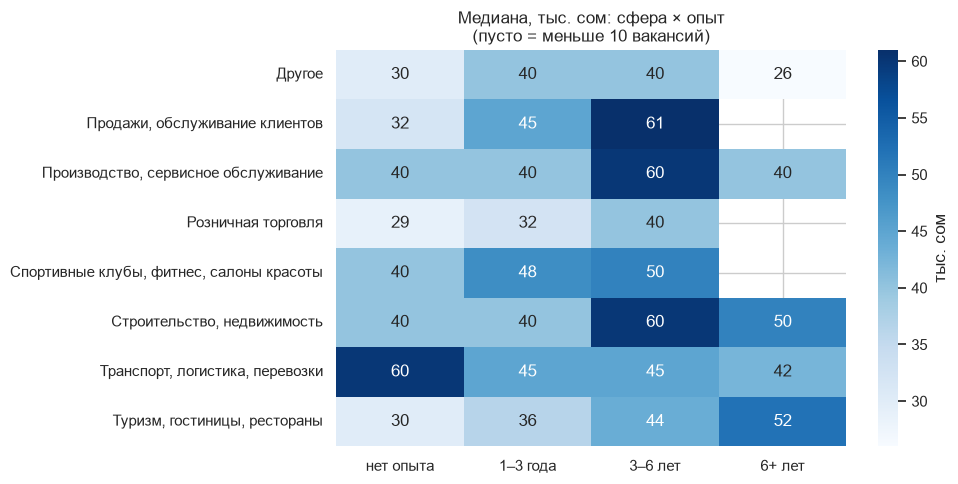

In [6]:
top_cat = sal["category"].value_counts().head(8).index
pv = (sal[sal["category"].isin(top_cat)]
      .groupby(["category", "experience"])["salary_kgs"]
      .agg(lambda s: s.median() if len(s) >= 10 else np.nan)
      .unstack()[order])
plt.figure(figsize=(10, 5))
sns.heatmap(pv / 1000, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "тыс. сом"})
plt.title("Медиана, тыс. сом: сфера × опыт\n(пусто = меньше 10 вакансий)")
plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.savefig(FIG + "03_q3_experience.png", dpi=150); plt.show()

**Вывод:** 1–3 года опыта дают +20% к медиане без опыта, 3–6 лет — +54%. На 6+ лет медиана ниже (+38%):
таких вакансий мало (216) и именно они чаще всего скрывают зарплату (см. п. 5).
Эффект опыта сильно зависит от сферы: в транспорте опыт почти не влияет, в продажах и производстве — сильно.

## 4. Бишкек против регионов

In [7]:
city = median_by("city")
print(city)
# сравнение внутри одинаковых сфер, чтобы разница не объяснялась составом вакансий
both = sal.groupby(["category", "city"])["salary_kgs"].agg(["median", "size"]).unstack()
ok = (both["size"]["Бишкек"] >= 20) & (both["size"]["Регионы"] >= 10)
ratio = (both["median"]["Регионы"] / both["median"]["Бишкек"])[ok].sort_values()
print("\nРегионы / Бишкек внутри одной сферы (медиана отношений):", round(ratio.median(), 2))
ratio.round(2)

          median     n
city                  
Регионы  33800.0   678
Ош       37500.0   111
Бишкек   39000.0  5051

Регионы / Бишкек внутри одной сферы (медиана отношений): 0.87


category
Сельское хозяйство                          0.40
Спортивные клубы, фитнес, салоны красоты    0.74
Продажи, обслуживание клиентов              0.76
Маркетинг, реклама, PR                      0.78
Наука, образование                          0.80
Транспорт, логистика, перевозки             0.82
Административный персонал                   0.85
Строительство, недвижимость                 0.87
Автомобильный бизнес                        1.00
Другое                                      1.00
Производство, сервисное обслуживание        1.00
Розничная торговля                          1.00
Туризм, гостиницы, рестораны                1.01
Финансы, бухгалтерия                        1.12
Домашний, обслуживающий персонал            1.25
dtype: float64

**Вывод:** внутри одной и той же сферы регионы платят в среднем на ~13% меньше Бишкека
(медиана отношений 0,87), сильнее всего разрыв в сельском хозяйстве и фитнесе/красоте.
83% вакансий — Бишкек, поэтому для регионов выводы менее надёжны.

## 5. Кто скрывает зарплату

Половина вакансий не указывает зарплату. Вопрос для проекта: скрывают ли её в
**высокооплачиваемых** сферах? Если да, то видимые зарплаты занижают картину рынка —
и это аргумент в пользу модели, которая оценит скрытые зарплаты.

In [8]:
print("Скрыли зарплату:", f"{df['salary_hidden'].mean():.0%}")
print(df.groupby("source")["salary_hidden"].mean().round(2))
print(df.groupby("experience")["salary_hidden"].mean().reindex(order).round(2))

Скрыли зарплату: 52%
source
headhunter    0.41
lalafo        0.56
Name: salary_hidden, dtype: float64
experience
нет опыта    0.48
1–3 года     0.51
3–6 лет      0.59
6+ лет       0.63
Name: salary_hidden, dtype: float64


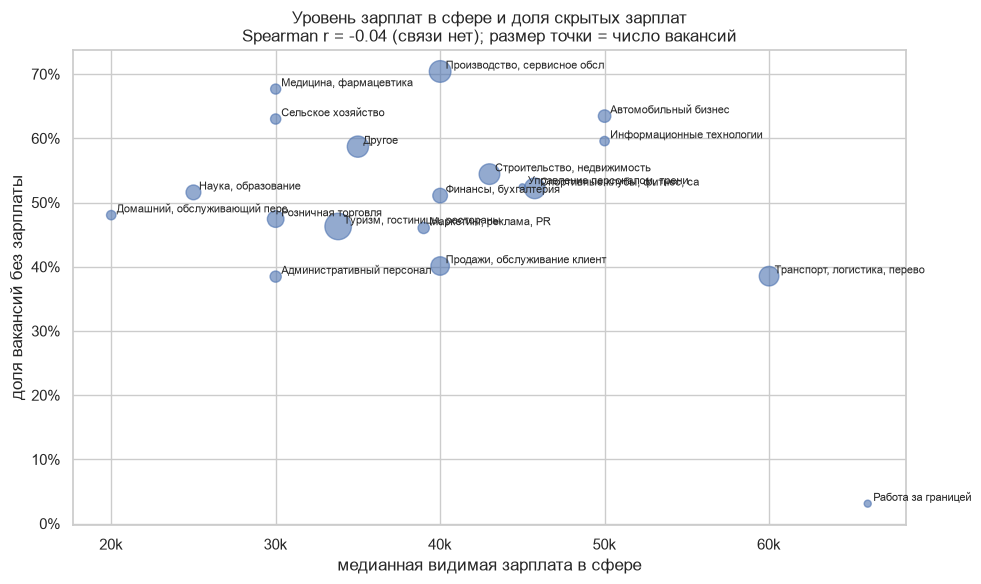

In [9]:
h = df.groupby("category").agg(hidden=("salary_hidden", "mean"), n=("id", "size"))
h = h.join(cat["median"]).dropna()
r = h["hidden"].corr(h["median"], method="spearman")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(h["median"], h["hidden"], s=h["n"] / 5, alpha=.6)
for name, row in h.iterrows():
    ax.annotate(name[:28], (row["median"], row["hidden"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.xaxis.set_major_formatter(K); ax.yaxis.set_major_formatter(mt.PercentFormatter(1))
ax.set_xlabel("медианная видимая зарплата в сфере"); ax.set_ylabel("доля вакансий без зарплаты")
ax.set_title(f"Уровень зарплат в сфере и доля скрытых зарплат\nSpearman r = {r:.2f} (связи нет); размер точки = число вакансий")
plt.tight_layout(); plt.savefig(FIG + "03_q5_hidden.png", dpi=150); plt.show()

**Вывод:** 52% вакансий скрывают зарплату (lalafo 56%, hh 41%). Гипотеза «скрывают в дорогих сферах»
**не подтвердилась** (r ≈ 0). Зато скрытность растёт с опытом: без опыта 48%, 6+ лет — 63%.
Значит, видимые зарплаты **занижают** оплату опытных специалистов — именно эту часть рынка
должна оценить модель.

## 6. Какие навыки повышают зарплату

Навыки есть почти только на hh, поэтому сравниваем **внутри hh**: медиана вакансий с навыком
против медианы hh в целом. Это связь, а не причина: навык может просто встречаться
в более дорогих профессиях.

Медиана hh: 40,000 | вакансий hh с зарплатой и навыками: 1313


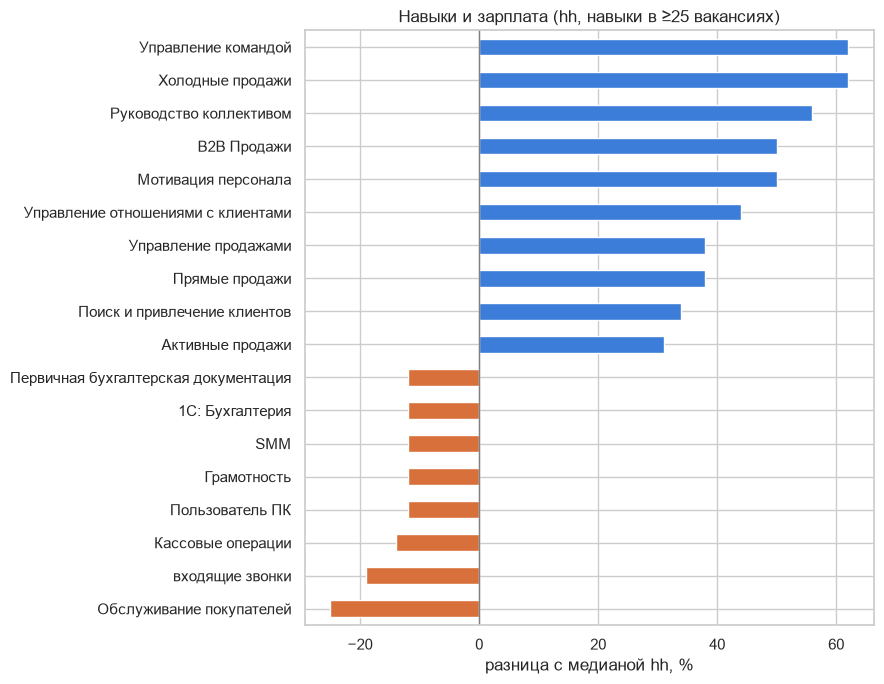

In [10]:
hh = sal[sal["source"] == "headhunter"].copy()
hh["skills_list"] = hh["skills"].fillna("").str.split(",").apply(lambda xs: [x.strip() for x in xs if x.strip()])
ex = hh.explode("skills_list").dropna(subset=["skills_list"])
base = hh["salary_kgs"].median()
sk = ex.groupby("skills_list")["salary_kgs"].agg(["median", "size"])
sk = sk[sk["size"] >= 25]
sk["премия_%"] = ((sk["median"] / base - 1) * 100).round(0)
print(f"Медиана hh: {base:,.0f} | вакансий hh с зарплатой и навыками: {hh['skills'].notna().sum()}")

show = pd.concat([sk.nlargest(10, "премия_%"), sk.nsmallest(8, "премия_%")]).sort_values("премия_%")
ax = show["премия_%"].plot(kind="barh", figsize=(9, 7),
                           color=np.where(show["премия_%"] >= 0, "#3b7dd8", "#d8703b"))
ax.axvline(0, color="grey", lw=1); ax.set_xlabel("разница с медианой hh, %")
ax.set_title("Навыки и зарплата (hh, навыки в ≥25 вакансиях)"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG + "03_q6_skills.png", dpi=150); plt.show()

In [11]:
# количество навыков в вакансии и зарплата
hh["n_skills_bin"] = pd.cut(hh["n_skills"], [-1, 0, 3, 6, 100], labels=["0", "1–3", "4–6", "7+"])
hh.groupby("n_skills_bin", observed=True)["salary_kgs"].agg(["median", "size"])

,median,size
n_skills_bin,,
0,40000.000,715
1–3,37096.875,344
4–6,40000.000,481
7+,45000.000,488


**Вывод:** выше всего оплачиваются навыки **продаж и управления людьми** (холодные и B2B-продажи,
управление командой: +50–62% к медиане hh). Ниже медианы — массовые навыки обслуживания:
кассовые операции, входящие звонки, обслуживание покупателей. Пример того, что категория
скрывает разброс: медиана IT — 50 000, но на hh 82 500, а на lalafo 30 000.

## 7. Влияет ли требование к образованию на зарплату

Сравнивать «в лоб» нельзя: высшее образование требуют в одних сферах чаще, чем в других.
Поэтому сравниваем **внутри каждой сферы** и берём медиану разниц.

In [12]:
print(df["education"].value_counts(normalize=True).round(3))
print()
print(median_by("education", min_n=20))

education
не указано             0.905
высшее                 0.091
среднее специальное    0.004
Name: proportion, dtype: float64

                      median     n
education                         
не указано           39000.0  5359
среднее специальное  39000.0    28
высшее               40000.0   453


Сфер для сравнения: 14 | медианная разница внутри сферы: +7%


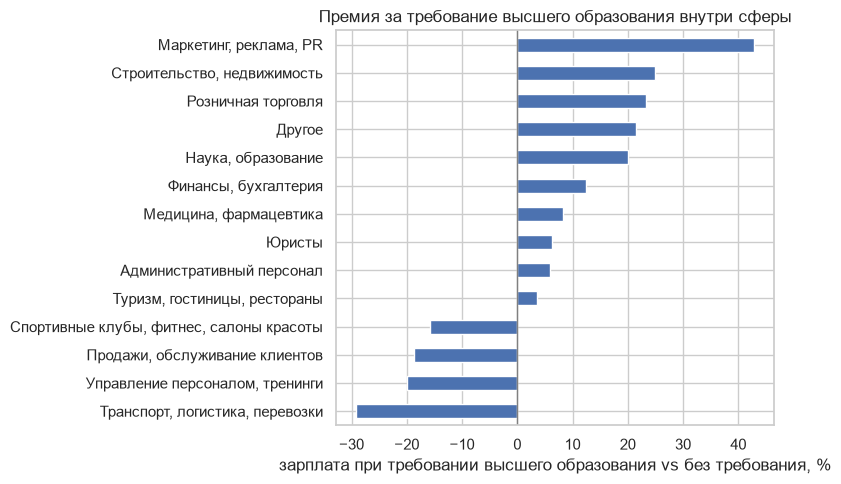

In [13]:
e = sal.groupby(["category", "education"])["salary_kgs"].agg(["median", "size"]).unstack()
okc = (e["size"]["высшее"] >= 10) & (e["size"]["не указано"] >= 10)
diff = ((e["median"]["высшее"] / e["median"]["не указано"] - 1) * 100)[okc].sort_values()
print(f"Сфер для сравнения: {okc.sum()} | медианная разница внутри сферы: {diff.median():+.0f}%")
ax = diff.plot(kind="barh", figsize=(8, 5)); ax.axvline(0, color="grey", lw=1)
ax.set_xlabel("зарплата при требовании высшего образования vs без требования, %")
ax.set_title("Премия за требование высшего образования внутри сферы"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG + "03_q7_education.png", dpi=150); plt.show()

> Ограничение: вакансии описывают требования работодателя, а не образование работника.
> Вопрос «помогает ли диплом найти работу» стоит дополнить официальной статистикой занятости
> по уровню образования (ILOSTAT / stat.gov.kg).

**Вывод:** высшее образование упоминается лишь в 9% вакансий. Внутри одной сферы такие вакансии
платят в среднем всего на ~7% больше. Для работодателей опыт и навыки важнее диплома.

## 8. Требования к полу в объявлениях

Объявлений с требованием к полу: 1180 (9.3%)
source
headhunter    0.000
lalafo        0.128
Name: gender_req, dtype: float64


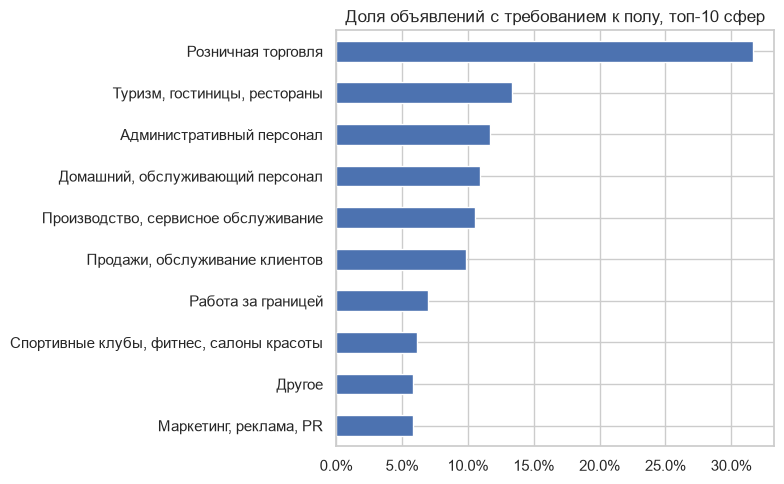

In [14]:
g = df[df["gender_req"] != "не указано"]
print(f"Объявлений с требованием к полу: {len(g)} ({len(g)/len(df):.1%})")
print(df.groupby("source")["gender_req"].apply(lambda s: (s != "не указано").mean()).round(3))
gc = (df.assign(g=df["gender_req"].isin(["женщины", "мужчины"]))
        .groupby("category")["g"].agg(["mean", "size"]))
gc = gc[gc["size"] >= 100].sort_values("mean").tail(10)
ax = gc["mean"].plot(kind="barh", figsize=(8, 5)); ax.xaxis.set_major_formatter(mt.PercentFormatter(1))
ax.set_title("Доля объявлений с требованием к полу, топ-10 сфер"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG + "03_q8_gender.png", dpi=150); plt.show()

In [15]:
median_by("gender_req", min_n=30)

,median,n
gender_req,,
женщины,30000.0,388
мужчины,35700.0,100
не указано,39500.0,5286
оба указаны,40000.0,66


**Вывод:** 9% объявлений указывают пол — **все они на lalafo** (12,8% объявлений), на hh таких нет.
Чаще всего требуют женщин. Вакансии «для женщин» имеют медиану 30 000 против 39 500 у вакансий
без требования, и в 5 из 8 сравнимых сфер они платят на 11–25% меньше. Это связь, а не доказательство
дискриминации: такие вакансии могут отличаться должностями внутри сферы.

## 9. Дневная оплата и графики работы

In [16]:
pp = sal.groupby("category")["pay_period"].apply(lambda s: (s == "day").mean())
print("Доля зарплат, указанных за день:", f"{(sal['pay_period'] == 'day').mean():.0%}")
print(pp.sort_values(ascending=False).head(6).round(2))
print()
print(median_by("schedule", min_n=30))

Доля зарплат, указанных за день: 18%
category
Туризм, гостиницы, рестораны        0.53
Автомобильный бизнес                0.31
Другое                              0.20
Строительство, недвижимость         0.17
Розничная торговля                  0.14
Домашний, обслуживающий персонал    0.13
Name: pay_period, dtype: float64

            median     n
schedule                
2/2        30420.0    97
6/1        35000.0   354
5/2        39000.0   213
не указан  39000.0  5080


**Вывод:** 18% указанных зарплат — дневные ставки; в общепите и гостиницах это больше половины.
График 2/2 оплачивается ниже всего (медиана ~30 000).

## 10. Связи признаков с зарплатой (для модели)

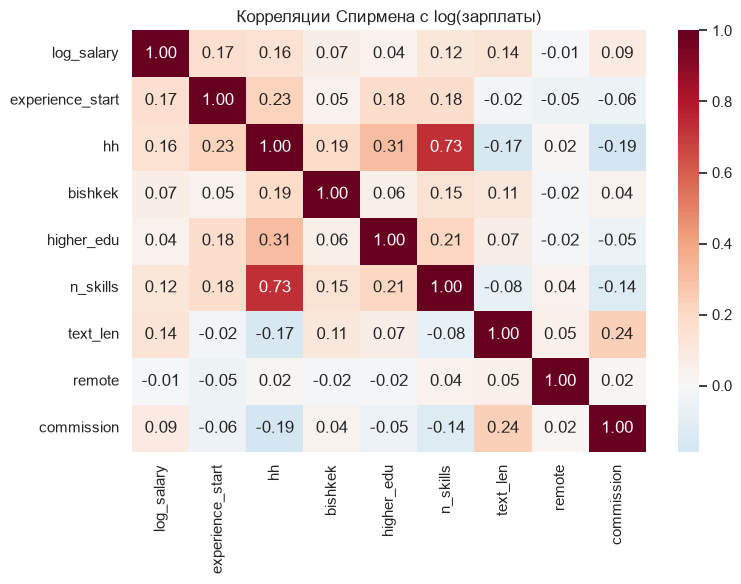

In [17]:
feat = sal.assign(remote=sal["remote"].astype(int), commission=sal["commission"].astype(int),
                  hh=(sal["source"] == "headhunter").astype(int),
                  bishkek=(sal["city"] == "Бишкек").astype(int),
                  higher_edu=(sal["education"] == "высшее").astype(int),
                  log_salary=np.log(sal["salary_kgs"]))
cols = ["log_salary", "experience_start", "hh", "bishkek", "higher_edu", "n_skills",
        "text_len", "remote", "commission"]
plt.figure(figsize=(8, 6))
sns.heatmap(feat[cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Корреляции Спирмена с log(зарплаты)")
plt.tight_layout(); plt.savefig(FIG + "03_q10_corr.png", dpi=150); plt.show()

## Итоги анализа

Данные: 12 646 вакансий hh.kg и lalafo.kg (февраль–март 2024), 5 840 с правдоподобной зарплатой.

| # | Вопрос | Ответ |
|---|---|---|
| 1 | Типичная зарплата | медиана 39 000 сом; hh 40 000, lalafo 35 000 — два разных рынка |
| 2 | Самые оплачиваемые сферы | работа за границей, транспорт и логистика (60 000), IT и авто (50 000) |
| 3 | Опыт | 3–6 лет: +54% к «без опыта»; эффект зависит от сферы |
| 4 | Регионы | на ~13% ниже Бишкека внутри той же сферы |
| 5 | Скрытые зарплаты | 52% вакансий; не зависит от уровня оплаты сферы, но растёт с опытом (48% → 63%) |
| 6 | Навыки | продажи и управление людьми: +50–62%; массовое обслуживание: ниже медианы |
| 7 | Образование | упоминается в 9% вакансий, премия внутри сферы ~7% |
| 8 | Пол | 9% объявлений (только lalafo), «женские» вакансии в основном платят меньше |
| 9 | Дневная оплата | 18% зарплат, в общепите больше половины |

**Для ML-модели:** главные признаки — сфера и подкатегория, опыт, источник, город, навыки;
предсказывать стоит log(зарплаты). Модель особенно полезна для опытных специалистов:
именно их зарплаты чаще всего скрыты.

**Ограничения:** данные — снимок начала 2024; на hh зарплаты «от X» — нижняя граница (на lalafo это просто формат, см. 04);
текстовые правила (период оплаты, образование, пол) ошибаются на части объявлений.

> Перед защитой перескажите эти выводы своими словами.